# Task 1: Multi-Class Benchmark Classification Pipeline

## Iris Dataset Classification

**Objective:** Build and evaluate supervised classification models using Logistic Regression and Decision Tree.

**Dataset:** Iris CSV provided by Datheon.

**Libraries:** Python, Pandas, Scikit-Learn, Seaborn, Matplotlib.

**Evaluation Metrics:** Accuracy, Precision, Recall, and F1-score.

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [18]:

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


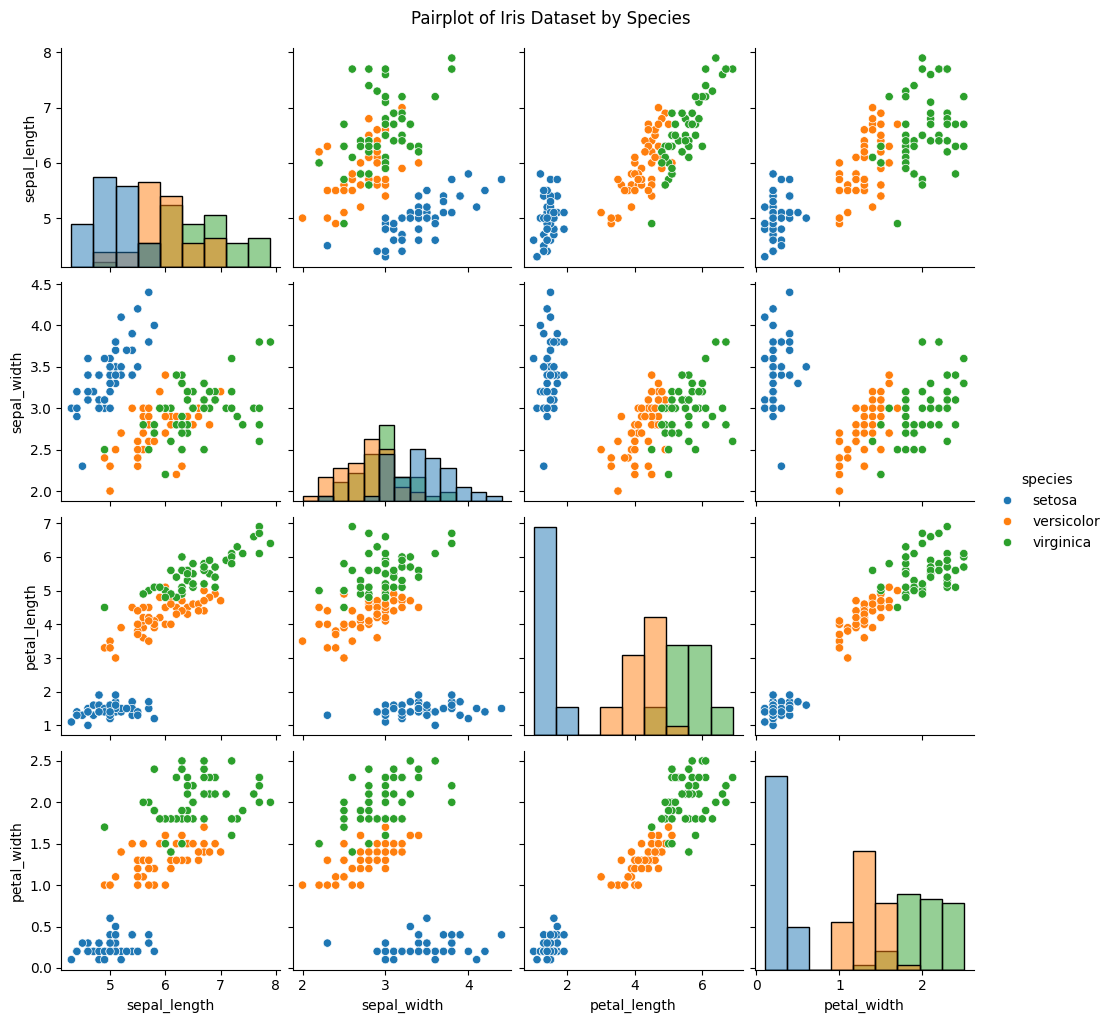

In [19]:

# Pairplot to visualize relationships between features
sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Pairplot of Iris Dataset by Species", y=1.02)
plt.show()


In [20]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Summary statistics
print("\nSummary Statistics:")
display(df.describe())

# Count each flower species
print("\nSpecies Distribution:")
print(df["species"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Summary Statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [21]:

# Separate input features and target variable
X = df.drop("species", axis=1)
y = df["species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget labels:")
print(y.head())


Feature shape: (150, 4)
Target shape: (150,)

Input features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target labels:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [22]:

# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nSpecies distribution in training data:")
print(y_train.value_counts())

print("\nSpecies distribution in testing data:")
print(y_test.value_counts())


Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)

Species distribution in training data:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Species distribution in testing data:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [23]:

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape after scaling:", X_train_scaled.shape)
print("Testing data shape after scaling:", X_test_scaled.shape)

print("\nMean of scaled training features:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nStandard deviation of scaled training features:")
print(X_train_scaled.std(axis=0).round(3))


Training data shape after scaling: (120, 4)
Testing data shape after scaling: (30, 4)

Mean of scaled training features:
[-0.  0.  0.  0.]

Standard deviation of scaled training features:
[1. 1. 1. 1.]


In [24]:

# Initialize the classification models
logistic_model = LogisticRegression(max_iter=200, random_state=42)
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train both models
logistic_model.fit(X_train_scaled, y_train)
decision_tree_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print("Decision Tree model trained successfully!")


Logistic Regression model trained successfully!
Decision Tree model trained successfully!


In [25]:
# Make predictions using both models
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_tree = decision_tree_model.predict(X_test_scaled)

# Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic, average="weighted"),
        precision_score(y_test, y_pred_tree, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic, average="weighted"),
        recall_score(y_test, y_pred_tree, average="weighted")
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_logistic, average="weighted"),
        f1_score(y_test, y_pred_tree, average="weighted")
    ]
})

print("Model Performance Comparison:")
display(results.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [26]:
# Classification report for Logistic Regression
print("CLASSIFICATION REPORT: LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_logistic))

# Classification report for Decision Tree
print("\nCLASSIFICATION REPORT: DECISION TREE")
print(classification_report(y_test, y_pred_tree))

CLASSIFICATION REPORT: LOGISTIC REGRESSION
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


CLASSIFICATION REPORT: DECISION TREE
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



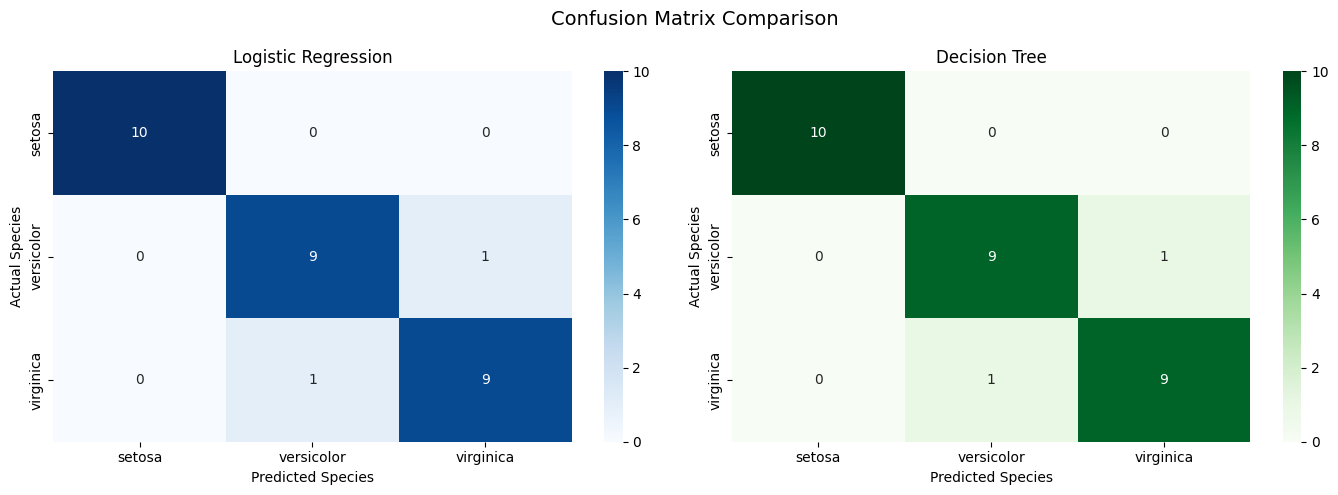

In [27]:
# Calculate confusion matrices
cm_logistic = confusion_matrix(
    y_test, y_pred_logistic,
    labels=["setosa", "versicolor", "virginica"]
)

cm_tree = confusion_matrix(
    y_test, y_pred_tree,
    labels=["setosa", "versicolor", "virginica"]
)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["setosa", "versicolor", "virginica"],
    yticklabels=["setosa", "versicolor", "virginica"],
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["setosa", "versicolor", "virginica"],
    yticklabels=["setosa", "versicolor", "virginica"],
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.suptitle("Confusion Matrix Comparison", fontsize=14)
plt.tight_layout()
plt.show()

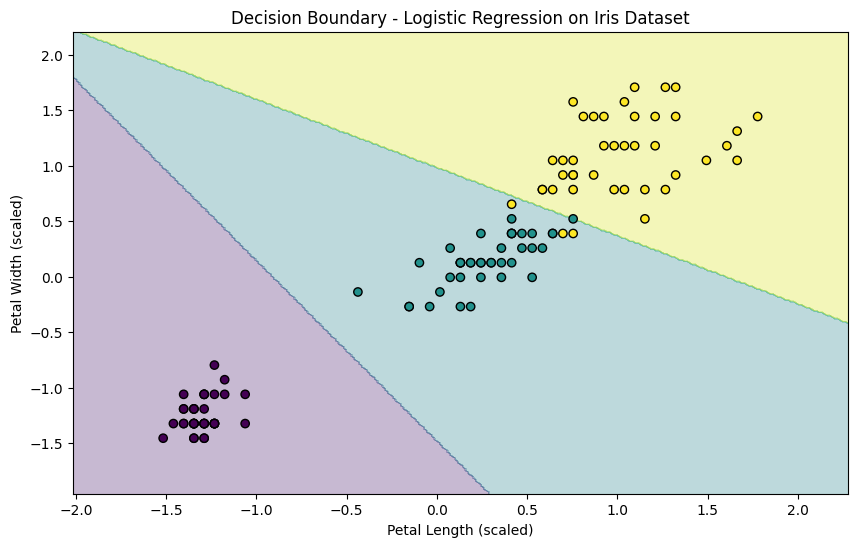

In [28]:
# Select two features for 2D visualization
features_2d = ["petal_length", "petal_width"]

X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

# Scale the selected features
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Train a separate Logistic Regression model for visualization
boundary_model = LogisticRegression(max_iter=200, random_state=42)
boundary_model.fit(X_train_2d_scaled, y_train)

# Create a grid covering the feature space
x_min, x_max = X_train_2d_scaled[:, 0].min() - 0.5, X_train_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_2d_scaled[:, 1].min() - 0.5, X_train_2d_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict the species for every point in the grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = boundary_model.predict(grid_points)
Z = pd.Series(Z).map({
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}).to_numpy().reshape(xx.shape)

# Convert species labels to numeric values for plotting
species_codes = y_train.map({
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
})

# Plot the decision regions and training samples
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

scatter = plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=species_codes,
    cmap="viridis",
    edgecolors="black"
)

plt.xlabel("Petal Length (scaled)")
plt.ylabel("Petal Width (scaled)")
plt.title("Decision Boundary - Logistic Regression on Iris Dataset")
plt.show()

## Conclusion

In this project, a multi-class classification pipeline was developed using the Iris dataset. Exploratory data analysis was performed using Seaborn pairplots, and the input features were standardized using StandardScaler. The dataset was divided into 80% training data and 20% testing data.

Two classification algorithms, Logistic Regression and Decision Tree, were trained and evaluated using accuracy, precision, recall, and F1-score. Both models achieved **93.33% accuracy** on the test dataset. Confusion-matrix heatmaps were plotted to visualize the correct and incorrect predictions, and a decision-boundary visualization was created using petal length and petal width.

This project demonstrates the application of data preprocessing, model training, evaluation, and visualization in a multi-class classification problem.